# Lasso (p = 1) with $\eta$ chosen by cross-validation

Minimize $\tfrac12\lVert y - X\beta\rVert^2 + \eta\sum_j\lvert\beta_j\rvert$ on the hedonic model from section 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso

RAW = "https://raw.githubusercontent.com/ajavakhishvili16/APMA-PROJECT/main/"
train = pd.read_csv(RAW + "training_set_2023_2025_clean-2.csv", low_memory=False)
test = pd.read_csv(RAW + "test_set_2026_clean-2.csv", low_memory=False)
ols_ref = pd.read_csv(RAW + "coefficients-1.csv", index_col=0)
print(len(train), len(test))

21783 8458


## Design matrix

In [2]:
BASE = {"exposure": "1-lot", "medium_c": "oil", "support_c": "canvas",
        "season": "Q1", "created_period": "1945_69"}

def design(d, columns=None):
    parts = []
    for col, base in BASE.items():
        dm = pd.get_dummies(d[col], prefix=col, prefix_sep=": ").astype(float)
        parts.append(dm.drop(columns=[f"{col}: {base}"], errors="ignore"))
    parts.append(d[["fame", "ln_area", "ln_area2"]].astype(float))
    X = pd.concat(parts, axis=1)
    return X if columns is None else X.reindex(columns=columns, fill_value=0.0)

X_train = design(train)
names = list(X_train.columns)
X_test = design(test, names)
y_train, y_test = train["ln_ppa"].to_numpy(), test["ln_ppa"].to_numpy()

# OLS on this matrix should match coefficients-1.csv
A = np.column_stack([np.ones(len(X_train)), X_train.to_numpy()])
ols = pd.Series(np.linalg.lstsq(A, y_train, rcond=None)[0], index=["Intercept"] + names)
print(X_train.shape, (ols - ols_ref["coef"].reindex(ols.index)).abs().max())

(21783, 24) 1.2434497875801753e-14


## Lasso by coordinate descent

```
LASSO(X, y, η):
    G ← XᵀX;  c ← Xᵀy
    β ← 0
    repeat
        for j = 1 … d:
            ρ_j ← c_j − Σ_{k≠j} G_jk β_k
            β_j ← S(ρ_j, η) / G_jj
    until max change in β < tol
    return β

S(ρ, η) = sign(ρ) · max(|ρ| − η, 0)
```

In [3]:
def soft_threshold(rho, eta):
    return np.sign(rho) * max(abs(rho) - eta, 0.0)

def lasso(X, y, eta, beta=None, tol=1e-10, max_sweeps=100000):
    G, c = X.T @ X, X.T @ y
    d = len(c)
    beta = np.zeros(d) if beta is None else beta.copy()
    for sweep in range(1, max_sweeps + 1):
        change = 0.0
        for j in range(d):
            rho = c[j] - G[j] @ beta + G[j, j] * beta[j]
            new = soft_threshold(rho, eta) / G[j, j]
            change = max(change, abs(new - beta[j]))
            beta[j] = new
        if change < tol:
            break
    return beta, sweep

def standardize(X, mean=None, sd=None):
    if mean is None:
        mean, sd = X.mean(axis=0), X.std(axis=0)
    return (X - mean) / sd, mean, sd

Z, x_mean, x_sd = standardize(X_train.to_numpy())
y_mean = y_train.mean()
yc = y_train - y_mean
n, d = Z.shape
eta_max = np.abs(Z.T @ yc).max()
print(n, d, eta_max)

21783 24 17752.002876577964


## Checks: $\eta = 0$ gives OLS, $\eta > 0$ matches scikit-learn

In [4]:
b0, sweeps = lasso(Z, yc, 0.0)
print("eta = 0:", sweeps, "sweeps, max diff from OLS", np.abs(b0 / x_sd - ols[names].to_numpy()).max())

for frac in [0.3, 0.05, 0.005]:
    eta = frac * eta_max
    b, sweeps = lasso(Z, yc, eta)
    sk = Lasso(alpha=eta / n, fit_intercept=False, tol=1e-14, max_iter=1000000).fit(Z, yc).coef_
    print(f"eta = {frac} eta_max: {sweeps} sweeps, {(b != 0).sum()} nonzero, max diff from sklearn {np.abs(b - sk).max():.1e}")

eta = 0: 1585 sweeps, max diff from OLS 6.3375087400174834e-09


eta = 0.3 eta_max: 6 sweeps, 2 nonzero, max diff from sklearn 9.9e-14


eta = 0.05 eta_max: 107 sweeps, 20 nonzero, max diff from sklearn 4.7e-10


eta = 0.005 eta_max: 1509 sweeps, 22 nonzero, max diff from sklearn 8.0e-09


## Choosing $\eta$

```
CHOOSE-ETA(X, y, grid, K):
    assign every artist to one of K folds
    for k = 1 … K:
        standardize using the other K − 1 folds
        for η in grid, largest first:
            β ← LASSO(other folds, η)
            err[η, k] ← mean squared error on fold k
    cv(η) ← mean over k of err[η, k]
    η* ← argmin cv(η)
    η_1se ← largest η with cv(η) ≤ cv(η*) + SE(η*)
    return η*, η_1se, LASSO(all data, η*)
```

In [5]:
K = 5
grid = np.append(eta_max * np.logspace(0, -4, 40), 0.0)

# folds by artist
rng = np.random.default_rng(0)
artist = pd.factorize(train["cluster"])[0]
fold = rng.permutation(artist.max() + 1)[artist] % K

Xn = X_train.to_numpy()
err = np.zeros((len(grid), K))
for k in range(K):
    tr, va = fold != k, fold == k
    Zk, m, s = standardize(Xn[tr])
    yk = y_train[tr].mean()
    Zv = (Xn[va] - m) / s
    beta = None
    for i, eta in enumerate(grid):
        beta, _ = lasso(Zk, y_train[tr] - yk, eta, beta)
        err[i, k] = np.mean((y_train[va] - yk - Zv @ beta) ** 2)

cv, cv_se = err.mean(axis=1), err.std(axis=1, ddof=1) / np.sqrt(K)
i_best = int(cv.argmin())
i_1se = int(np.where(cv <= cv[i_best] + cv_se[i_best])[0].min())
eta_best, eta_1se = grid[i_best], grid[i_1se]
print(f"eta*    = {eta_best:.2f}  (eta/n = {eta_best / n:.5f})  CV error {cv[i_best]:.4f} +/- {cv_se[i_best]:.4f}")
print(f"eta_1se = {eta_1se:.2f}  (eta/n = {eta_1se / n:.5f})  CV error {cv[i_1se]:.4f}")
print(f"eta = 0 (OLS)  CV error {cv[-1]:.4f}")

eta*    = 9.27  (eta/n = 0.00043)  CV error 2.0747 +/- 0.0556
eta_1se = 513.79  (eta/n = 0.02359)  CV error 2.1302
eta = 0 (OLS)  CV error 2.0749


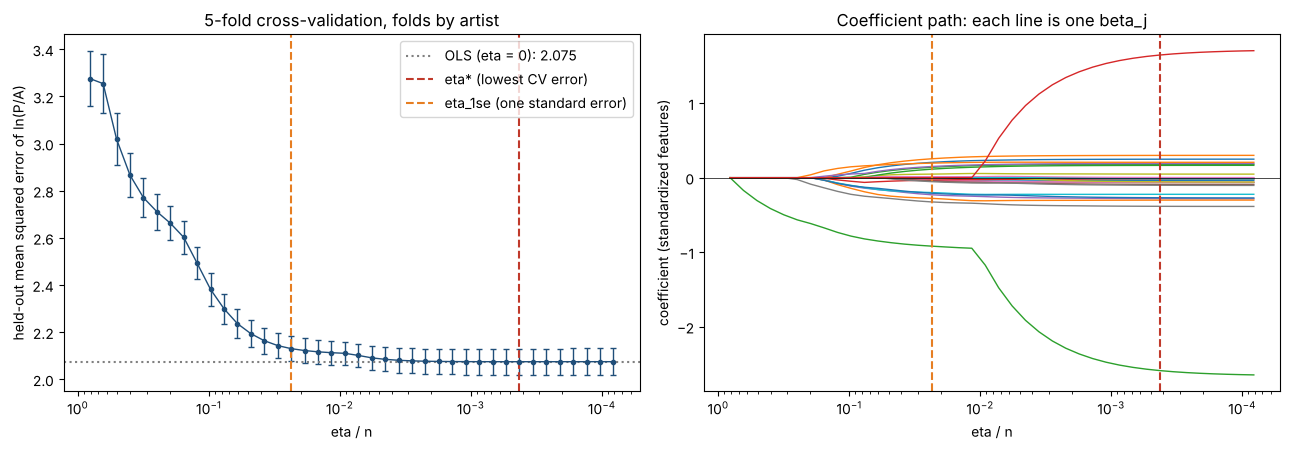

In [6]:
path = np.zeros((len(grid), d))
beta = None
for i, eta in enumerate(grid):
    beta, _ = lasso(Z, yc, eta, beta)
    path[i] = beta

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
x = grid[:-1] / n

ax[0].errorbar(x, cv[:-1], yerr=cv_se[:-1], fmt="o-", ms=3, lw=1, capsize=2, color="#1f4e79")
ax[0].axhline(cv[-1], ls=":", color="gray", label=f"OLS (eta = 0): {cv[-1]:.3f}")
ax[0].axvline(eta_best / n, ls="--", color="#c0392b", label="eta* (lowest CV error)")
ax[0].axvline(eta_1se / n, ls="--", color="#e67e22", label="eta_1se (one standard error)")
ax[0].set(xscale="log", xlabel="eta / n", ylabel="held-out mean squared error of ln(P/A)",
          title=f"{K}-fold cross-validation, folds by artist")
ax[0].legend()

ax[1].plot(x, path[:-1], lw=1)
ax[1].axvline(eta_best / n, ls="--", color="#c0392b")
ax[1].axvline(eta_1se / n, ls="--", color="#e67e22")
ax[1].axhline(0, color="black", lw=0.5)
ax[1].set(xscale="log", xlabel="eta / n", ylabel="coefficient (standardized features)",
          title="Coefficient path: each line is one beta_j")
for a in ax:
    a.invert_xaxis()
plt.tight_layout()
plt.savefig("lasso_cv_and_path.png", dpi=160)
plt.show()

## Coefficients at $\eta^*$ vs $\eta = 0$

In [7]:
def r2(y, pred):
    return 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)

Z_test = (X_test.to_numpy() - x_mean) / x_sd
table, rows = pd.DataFrame(index=names), []
for label, eta in {"OLS (eta = 0)": 0.0, "lasso at eta*": eta_best, "lasso at eta_1se": eta_1se}.items():
    b, _ = lasso(Z, yc, eta)
    table[label] = b / x_sd    # original units
    rows.append({"model": label, "eta / n": eta / n, "nonzero": int((b != 0).sum()),
                 "CV error": cv[list(grid).index(eta)],
                 "train R2": r2(y_train, y_mean + Z @ b),
                 "test R2 (2026)": r2(y_test, y_mean + Z_test @ b)})
table["OLS p-value"] = ols_ref["p"].reindex(names)

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(pd.DataFrame(rows).set_index("model").to_string(), "\n")
print(table.to_string())

                  eta / n  nonzero  CV error  train R2  test R2 (2026)
model                                                                 
OLS (eta = 0)      0.0000       24    2.0749    0.3766          0.3803
lasso at eta*      0.0004       24    2.0747    0.3766          0.3806
lasso at eta_1se   0.0236       20    2.1302    0.3608          0.3722 

                          OLS (eta = 0)  lasso at eta*  lasso at eta_1se  OLS p-value
exposure: circulating            0.6714         0.6693            0.5546       0.0000
exposure: established            0.8369         0.8348            0.7083       0.0000
exposure: local                  0.4333         0.4318            0.3368       0.0000
medium_c: acrylic               -0.0273        -0.0205            0.0425       0.7250
medium_c: drawing               -0.7267        -0.7219           -0.5895       0.0000
medium_c: ink                   -0.2024        -0.1987           -0.1152       0.0534
medium_c: mixed                 -0.4023  